# A visual history of Nobel Prize winners

The Nobel Prize has been awarded since 1901 in chemistry, literature, physics, medicine and peace, with economics added in 1969. This notebook uses the Nobel Foundation's list of laureates from 1901 to 2016 to look at who wins: where laureates were born, how the gender balance has changed, and how old winners are when they receive the prize.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

sns.set_theme()
plt.rcParams["figure.figsize"] = [11, 6]

nobel = pd.read_csv("datasets/nobel.csv")
print(nobel.shape)
nobel.head()

(911, 18)


,year,category,prize,motivation,prize_share,laureate_id,laureate_type,full_name,birth_date,birth_city,birth_country,sex,organization_name,organization_city,organization_country,death_date,death_city,death_country
0,1901,Chemistry,The Nobel Prize in Chemistry 1901,"""in recognition of the extraordinary services ...",1/1,160,Individual,Jacobus Henricus van 't Hoff,1852-08-30,Rotterdam,Netherlands,Male,Berlin University,Berlin,Germany,1911-03-01,Berlin,Germany
1,1901,Literature,The Nobel Prize in Literature 1901,"""in special recognition of his poetic composit...",1/1,569,Individual,Sully Prudhomme,1839-03-16,Paris,France,Male,NaN,NaN,NaN,1907-09-07,Châtenay,France
2,1901,Medicine,The Nobel Prize in Physiology or Medicine 1901,"""for his work on serum therapy, especially its...",1/1,293,Individual,Emil Adolf von Behring,1854-03-15,Hansdorf (Lawice),Prussia (Poland),Male,Marburg University,Marburg,Germany,1917-03-31,Marburg,Germany
3,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,462,Individual,Jean Henry Dunant,1828-05-08,Geneva,Switzerland,Male,NaN,NaN,NaN,1910-10-30,Heiden,Switzerland
4,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,463,Individual,Frédéric Passy,1822-05-20,Paris,France,Male,NaN,NaN,NaN,1912-06-12,Paris,France


## 1. Who gets the prize?

Each row is one prize share, so a prize split three ways appears three times. Organisations (30 rows) have no sex or birth country.

In [2]:
print("Prize shares awarded 1901-2016:", len(nobel))
display(nobel["sex"].value_counts())
nobel["birth_country"].value_counts().head(10)

Prize shares awarded 1901-2016: 911


sex
Male      836
Female     49
Name: count, dtype: int64

birth_country
United States of America    259
United Kingdom               85
Germany                      61
France                       51
Sweden                       29
Japan                        24
Netherlands                  18
Canada                       18
Russia                       17
Italy                        17
Name: count, dtype: int64

## 2. US dominance

Share of laureates born in the United States, by decade.

In [3]:
nobel["usa_born_winner"] = nobel["birth_country"] == "United States of America"
nobel["decade"] = (nobel["year"] // 10) * 10

prop_usa_winners = nobel.groupby("decade", as_index=False)["usa_born_winner"].mean()
prop_usa_winners.round(3)

,decade,usa_born_winner
0,1900,0.018
1,1910,0.075
2,1920,0.074
3,1930,0.250
4,1940,0.302
5,1950,0.292
6,1960,0.266
7,1970,0.317
8,1980,0.320
9,1990,0.404


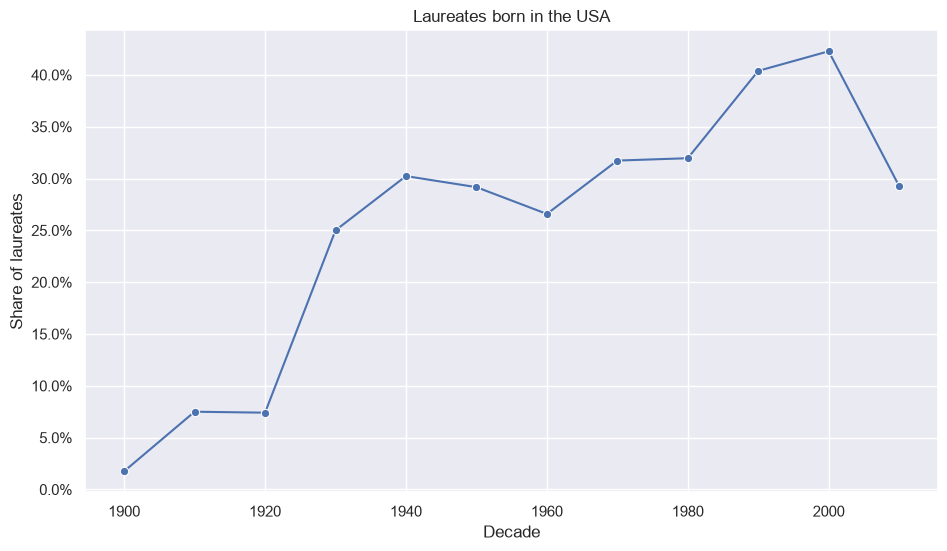

In [4]:
ax = sns.lineplot(x="decade", y="usa_born_winner", data=prop_usa_winners, marker="o")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Decade")
ax.set_ylabel("Share of laureates")
ax.set_title("Laureates born in the USA")
plt.show()

## 3. Gender

Share of female laureates by decade and category.

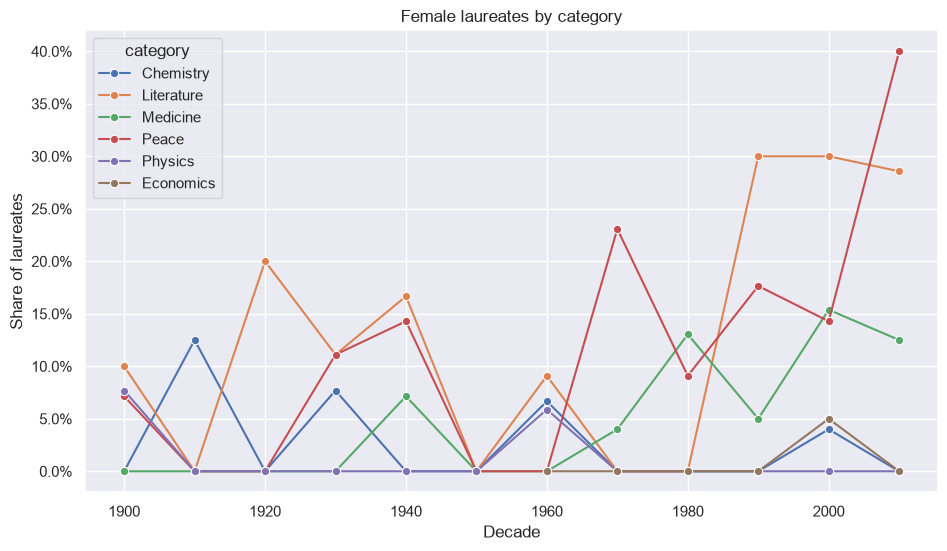

In [5]:
nobel["female_winner"] = nobel["sex"] == "Female"
prop_female_winners = nobel.groupby(["decade", "category"], as_index=False)["female_winner"].mean()

ax = sns.lineplot(x="decade", y="female_winner", hue="category", data=prop_female_winners, marker="o")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Decade")
ax.set_ylabel("Share of laureates")
ax.set_title("Female laureates by category")
plt.show()

In [6]:
nobel.groupby("category")["female_winner"].agg(female="sum", total="count").assign(
    share_pct=lambda d: (d["female"] / d["total"] * 100).round(1)).sort_values("share_pct", ascending=False)

,female,total,share_pct
category,,,
Literature,14,113,12.4
Peace,16,130,12.3
Medicine,12,211,5.7
Chemistry,4,175,2.3
Economics,1,78,1.3
Physics,2,204,1.0


The first woman to win:

In [7]:
nobel[nobel["sex"] == "Female"].nsmallest(1, "year")[["year", "category", "full_name", "birth_country", "prize_share"]]

,year,category,full_name,birth_country,prize_share
19,1903,Physics,"Marie Curie, née Sklodowska",Russian Empire (Poland),1/4


## 4. Repeat laureates

In [8]:
repeat = nobel.groupby("full_name").filter(lambda group: len(group) >= 2)
repeat[["year", "category", "full_name", "laureate_type"]].sort_values(["full_name", "year"])

,year,category,full_name,laureate_type
89,1917,Peace,Comité international de la Croix Rouge (Intern...,Organization
215,1944,Peace,Comité international de la Croix Rouge (Intern...,Organization
348,1963,Peace,Comité international de la Croix Rouge (Intern...,Organization
306,1958,Chemistry,Frederick Sanger,Individual
505,1980,Chemistry,Frederick Sanger,Individual
298,1956,Physics,John Bardeen,Individual
424,1972,Physics,John Bardeen,Individual
278,1954,Chemistry,Linus Carl Pauling,Individual
340,1962,Peace,Linus Carl Pauling,Individual
19,1903,Physics,"Marie Curie, née Sklodowska",Individual


## 5. Age at the time of the prize

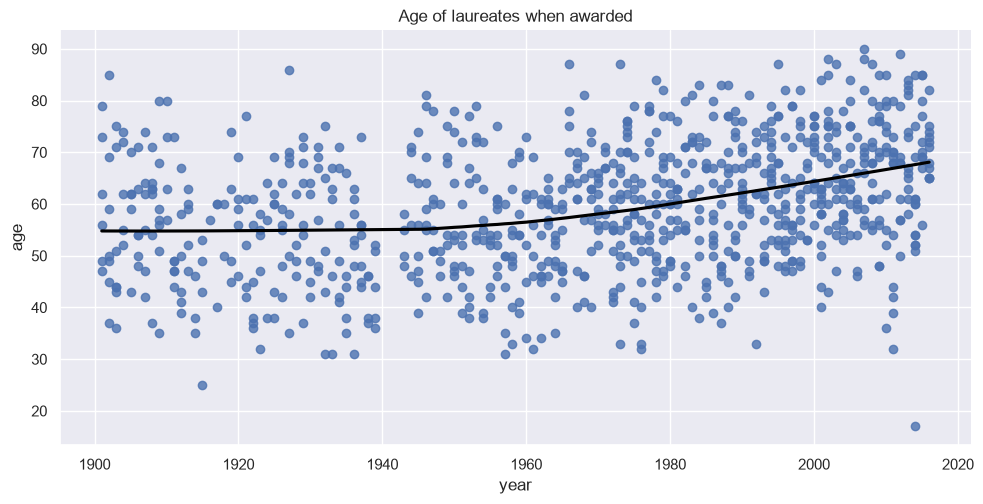

In [9]:
nobel["birth_date"] = pd.to_datetime(nobel["birth_date"])
nobel["age"] = nobel["year"] - nobel["birth_date"].dt.year

sns.lmplot(x="year", y="age", data=nobel, lowess=True, aspect=2, line_kws={"color": "black"})
plt.title("Age of laureates when awarded")
plt.show()

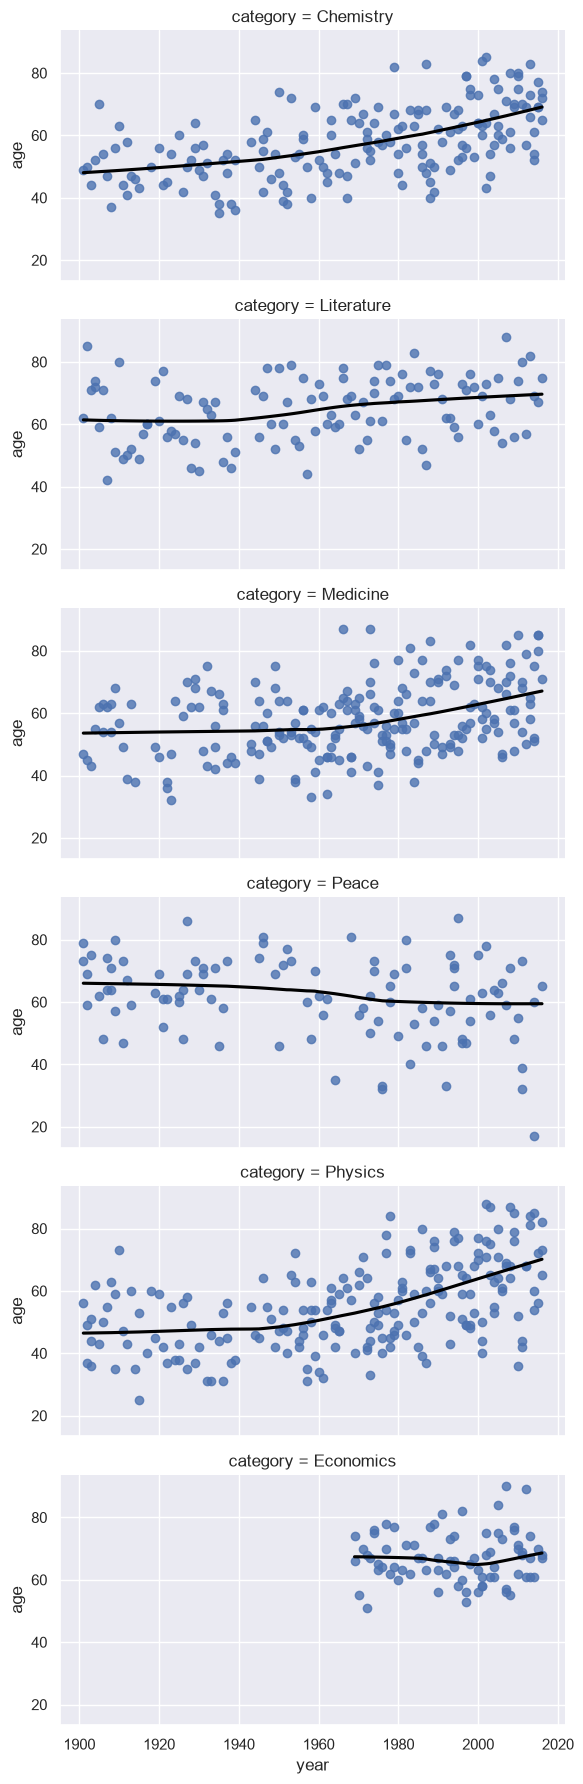

In [10]:
sns.lmplot(x="year", y="age", row="category", data=nobel, lowess=True, aspect=2, height=3, line_kws={"color": "black"})
plt.show()

In [11]:
nobel.groupby("decade")["age"].mean().round(1).loc[[1900, 1950, 2000, 2010]]

decade
1900    57.8
1950    54.3
2000    65.9
2010    66.2
Name: age, dtype: float64

Oldest and youngest laureates:

In [12]:
display(nobel.nlargest(1, "age")[["year", "category", "full_name", "age"]])
display(nobel.nsmallest(1, "age")[["year", "category", "full_name", "age"]])

,year,category,full_name,age
793,2007,Economics,Leonid Hurwicz,90.0


,year,category,full_name,age
885,2014,Peace,Malala Yousafzai,17.0


## Findings

- **Country of birth:** 259 prize shares went to people born in the United States, three times as many as the next country (United Kingdom, 85). The US share was about 2% in the 1900s, 25-30% from the 1930s on, and peaked at 42% in the 2000s.
- **Gender:** 49 of the 885 shares awarded to individuals went to women. Literature and Peace are the least unbalanced categories (about 12% each); Physics (1.0%) and Economics (1.3%) are the most. Marie Curie was the first female laureate, in 1903.
- **Repeat winners:** very few. The International Committee of the Red Cross has received the Peace Prize three times, and a handful of individuals, including Marie Curie, Linus Pauling, John Bardeen and Frederick Sanger, have won twice.
- **Age:** laureates are getting older. The average age at award was 58 in the 1900s, 54 in the 1950s and 66 in the 2000s. Peace is the exception: its winners have not become older, and the 2010s average is 49. The oldest laureate in the data is Leonid Hurwicz (90, Economics 2007) and the youngest Malala Yousafzai (17, Peace 2014).

The data ends in 2016, so the 2010s figures cover only seven years.